# 04 · Modelo supervisado: ¿quién tendrá continuidad el próximo año?

**Objetivo:** `y = 1` si la persona tiene **9 meses o más** cubiertos en *t+1*, usando **solo variables de t**.
La población son las personas activas en *t*. Si alguien no aparece en *t+1*, su objetivo es 0.

**Partición temporal** (no aleatoria, para imitar el uso real), siempre hacia adelante:
- **Validación:** se entrena con el par 2022→2023 y se valida con 2023→2024. Con esa validación se eligen los
  hiperparámetros, la calibración isotónica, el umbral de decisión y el modelo final.
- **Prueba:** el modelo final se entrena con 2022→2023 y 2023→2024 y se evalúa **una sola vez** con el par
  2024→2025.

**Cero leakage:**
- No se usa nada de *t+1* como variable.
- Tampoco `estado_contrato` ni `valor_pagado`, que son información posterior a la firma.
- Se excluye `dias_adicionados_total`, porque una prórroga registrada en *t+1* sobre un contrato de *t* cambia ese
  número.
- La cobertura de *t* se recortó al 31-dic de *t* y se calculó solo con contratos firmados en *t−1* y *t*.
- La tasa de renovación de cada entidad (*target encoding*) usa solo pares anteriores al de cada fila.

**Modelos y referencias:**
- Referencias: Dummy, persistencia ("score = meses en t"), contrato vigente al 31-dic y días ya firmados para
  *t+1*.
- Modelos: logística simple con 5 variables, logística completa, Random Forest y LightGBM, con y sin variables de
  entidad.

In [1]:
# --- Configuración común: rutas (Colab o local), constantes de ley y estilo de gráficas ---
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from cycler import cycler
warnings.filterwarnings('ignore')

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ_DRIVE = Path('/content/drive/MyDrive/Proyecto Final SECOP')
    DATA_DIR = RAIZ_DRIVE / 'data' / 'processed'
    assert DATA_DIR.exists(), (f'No encuentro {DATA_DIR}. Sube la carpeta "Proyecto Final SECOP" (con data/processed/'
                               'secop_ps_AAAA.parquet, ver README.md) a la raíz de "Mi unidad" y vuelve a ejecutar.')
    # Las salidas quedan en "Proyecto Final SECOP/proyecto_secop/" para que las rutas relativas funcionen
    CARPETA_NB = RAIZ_DRIVE / 'proyecto_secop' / 'notebooks'
    CARPETA_NB.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA_NB)
else:
    # Local: variable de entorno SECOP_DATA o, si no existe, la estructura del README relativa al notebook
    # (proyecto_secop/ junto a data/, o proyecto_secop/ dentro de la carpeta del proyecto).
    candidatos = [os.environ.get('SECOP_DATA'), '../data/processed', '../../data/processed']
    DATA_DIR = next((Path(c) for c in candidatos if c and Path(c).exists()), None)
    assert DATA_DIR is not None, ('No encuentro los parquet. Define la variable de entorno SECOP_DATA con la ruta a '
                                  'data/processed (ver README.md) o ubica proyecto_secop/ junto a la carpeta data/.')

# Salidas con rutas relativas a la carpeta notebooks/
OUT = Path('../outputs'); FIGS = OUT / 'figs'; TABLAS = OUT / 'tablas'; INTER = Path('../data_intermedia')
for _p in (FIGS, TABLAS, INTER):
    _p.mkdir(parents=True, exist_ok=True)
RESULTADOS = OUT / 'resultados.json'

# Constantes de ley (no son datos externos: salario mínimo decretado y regla del IBC del independiente)
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000,
         2024: 1_300_000, 2025: 1_423_500, 2026: 1_750_905}   # 2026: Decreto 1469 de 2025 (verificado)
FRACCION_IBC = 0.40          # el IBC del independiente es el 40% del honorario mensual
SEMANAS_PENSION = 1300       # semanas exigidas para pensión de vejez (Colpensiones)
DIAS_MES = 30.4375           # 365,25 / 12, para pasar duración en días a meses
SEMILLA = 42

# --- Estilo de gráficas para diapositivas: sobrio, letra grande, sin adornos ---
COLOR = {'azul': '#2a78d6', 'naranja': '#eb6834', 'aqua': '#1baf7a', 'amarillo': '#eda100',
         'magenta': '#e87ba4', 'verde': '#008300', 'violeta': '#6250d6', 'rojo': '#e34948',
         'gris': '#9b9a95', 'gris_claro': '#d9d8d3', 'tinta': '#0b0b0b', 'tinta2': '#52514e'}
SERIE = [COLOR[c] for c in ('azul', 'naranja', 'aqua', 'amarillo', 'magenta', 'verde', 'violeta', 'rojo')]
mpl.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.family': 'DejaVu Sans',
    'font.size': 15, 'axes.titlesize': 20, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 34, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.frameon': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9b9a95', 'axes.labelcolor': COLOR['tinta2'], 'xtick.color': COLOR['tinta2'],
    'ytick.color': COLOR['tinta2'], 'text.color': COLOR['tinta'], 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#ebeae6', 'grid.linewidth': 0.9, 'axes.axisbelow': True, 'lines.linewidth': 2.5,
    'axes.prop_cycle': cycler(color=SERIE)})

def titulo(ax, texto, sub=None):
    """Título que cuenta el hallazgo + subtítulo gris con el detalle."""
    ax.set_title(texto, loc='left')
    if sub:
        ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=13, color=COLOR['tinta2'], va='bottom')

def fuente(fig, texto='Fuente: SECOP II (datos.gov.co), contratos de prestación de servicios a personas naturales.'):
    fig.text(0.01, -0.02, texto, fontsize=10.5, color=COLOR['gris'], ha='left', va='top')

def guardar(fig, nombre):
    ruta = FIGS / f'{nombre}.png'
    fig.savefig(ruta)
    print('Figura guardada:', ruta)

def num(x, d=0):
    """Formato numérico en español: 1.234.567,8"""
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')

def pesos_millones(x, pos=None):
    return f'${num(x/1e6, 1)}M'

def pct(x, d=1):
    return f'{num(100*x, d)}%'

def guardar_resultados(seccion, datos):
    """Agrega/actualiza una sección en outputs/resultados.json."""
    todo = json.loads(RESULTADOS.read_text()) if RESULTADOS.exists() else {}
    todo[seccion] = datos
    RESULTADOS.write_text(json.dumps(todo, ensure_ascii=False, indent=2, default=float))
    print(f'resultados.json -> sección "{seccion}" actualizada')

print('Colab:', EN_COLAB, '| DATA_DIR:', DATA_DIR, '| existe:', DATA_DIR.exists())

import time, gc, subprocess
if EN_COLAB:   # en Colab pueden faltar estas librerías
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm', 'shap'], check=False)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, brier_score_loss, precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import shap

Colab: False | DATA_DIR: ../data/processed | existe: True


## 1. Construcción de los pares (t → t+1) y variables
Hay tres bloques de variables, todos medidos en *t*:
- **Persona (A):** cobertura, contratos, honorario, huecos, cuándo arrancó, si tenía contrato al cierre, etc.
- **Entidad (B):**
  - Del propio año *t*: tamaño de la entidad principal de la persona (número de contratistas), meses promedio
    de sus contratistas y % de ellos con contrato al cierre.
  - **Tasa histórica de renovación** de la entidad (*target encoding*): qué tanto renueva a sus contratistas al
    año siguiente, comparada con la tasa nacional de ese año. Se calcula **solo con pares anteriores** al de cada
    fila (ver más abajo).
- **Contexto del año (C):** si *t+1* es año de elecciones locales, de cambio de gobierno local o de elección
  presidencial (son hechos del calendario electoral, conocidos de antemano), y la tasa de continuidad observada
  *t−1 → t* (conocida al cierre de *t*).

In [2]:
import gc
COLS_PA = ['id_persona', 'anio', 'meses_cubiertos', 'dias_cubiertos', 'n_contratos', 'n_entidades', 'honorario_mensual_mediano',
           'valor_total', 'n_huecos', 'hueco_max_dias', 'mes_inicio_primer_contrato', 'cubierto_al_cierre',
           'dias_sin_contrato_al_cierre', 'nit_modal', 'share_entidad_nacional', 'share_objeto_profesional',
           'share_objeto_apoyo', 'genero', 'departamento_modal', 'sector_modal', 'justificacion_modal',
           'antiguedad_2_anios', 'meses_cubiertos_anio_anterior', 'smmlv', 'cotiza_minimo', 'dias_firmados_para_t1']
pa = pd.read_parquet(INTER / 'persona_anio_2022_2025.parquet', columns=COLS_PA)   # solo lo necesario (RAM)
cob = pd.read_parquet(INTER / 'cobertura_2020_2025.parquet', columns=['id_persona', 'anio', 'meses_cubiertos'])
pa['log_honorario_smmlv'] = np.log((pa.honorario_mensual_mediano / pa.smmlv).clip(0.05, 100))
pa['log_valor_total_smmlv'] = np.log1p((pa.valor_total / pa.smmlv).clip(0, 2000))
# Entidad, medida dentro del propio año t
ent = pa.groupby(['anio', 'nit_modal'], observed=True).agg(
    ent_n=('id_persona', 'size'), ent_meses_media=('meses_cubiertos', 'mean'),
    ent_pct_cierre=('cubierto_al_cierre', 'mean')).reset_index()
pa = pa.merge(ent, on=['anio', 'nit_modal'], how='left')
pa['ent_log_n'] = np.log(pa.ent_n)
# Contexto electoral de t+1 (calendario conocido de antemano)
CALENDARIO = {2023: 'elecciones_locales', 2024: 'cambio_gobierno_local', 2025: 'ninguno', 2026: 'presidencial'}
# Tasa de continuidad observada t-1 -> t (conocida al cierre de t). Para 2022 se usa 2021->2022 (cobertura parcial).
tasa_obs = {}
for t in (2022, 2023, 2024):
    act = cob[cob.anio == t - 1].set_index('id_persona')
    sig = cob[cob.anio == t].set_index('id_persona').meses_cubiertos
    tasa_obs[t] = float((act.index.map(sig).fillna(0) >= 9).mean())
print('Tasa de continuidad observada t-1 -> t:', {k: round(v, 3) for k, v in tasa_obs.items()})
del cob; gc.collect()

def construir_par(t):
    x = pa[pa.anio == t].copy()
    sig = pa[pa.anio == t + 1].set_index('id_persona').meses_cubiertos
    x['meses_t1'] = x.id_persona.map(sig).fillna(0.0)          # SOLO para el objetivo, nunca como variable
    x['y'] = (x.meses_t1 >= 9).astype(int)
    x['par'] = f'{t}→{t+1}'
    x['t1_elecciones_locales'] = int(CALENDARIO[t + 1] == 'elecciones_locales')
    x['t1_cambio_gobierno_local'] = int(CALENDARIO[t + 1] == 'cambio_gobierno_local')
    x['t1_presidencial'] = int(CALENDARIO[t + 1] == 'presidencial')
    x['tasa_continuidad_t'] = tasa_obs[t]
    return x[KEEP]

# Solo conservamos las columnas que se usan (cuidar la RAM)
KEEP = ['id_persona', 'nit_modal', 'meses_t1', 'y', 'par', 'dias_cubiertos', 'dias_firmados_para_t1',
        'meses_cubiertos', 'n_contratos', 'n_entidades', 'log_honorario_smmlv', 'log_valor_total_smmlv', 'n_huecos',
        'hueco_max_dias', 'mes_inicio_primer_contrato', 'cubierto_al_cierre', 'dias_sin_contrato_al_cierre',
        'share_entidad_nacional', 'share_objeto_profesional', 'share_objeto_apoyo', 'antiguedad_2_anios',
        'meses_cubiertos_anio_anterior', 'cotiza_minimo', 'ent_log_n', 'ent_meses_media', 'ent_pct_cierre',
        't1_elecciones_locales', 't1_cambio_gobierno_local', 't1_presidencial', 'tasa_continuidad_t',
        'genero', 'departamento_modal', 'sector_modal', 'justificacion_modal']

pares = {t: construir_par(t) for t in (2022, 2023, 2024)}
del pa; gc.collect()
for t, d in pares.items():
    print(f'{t}→{t+1}: {len(d):,} personas · tasa de continuidad (y=1) = {d.y.mean():.3f} · '
          f'no aparece en t+1 = {(d.meses_t1 == 0).mean():.3f}')

Tasa de continuidad observada t-1 -> t: {2022: 0.58, 2023: 0.505, 2024: 0.35}


2022→2023: 402,755 personas · tasa de continuidad (y=1) = 0.505 · no aparece en t+1 = 0.252
2023→2024: 437,494 personas · tasa de continuidad (y=1) = 0.350 · no aparece en t+1 = 0.368
2024→2025: 471,549 personas · tasa de continuidad (y=1) = 0.480 · no aparece en t+1 = 0.260


### Target encoding de la entidad: solo con el pasado
Para cada entidad calculamos qué tanto renueva a sus contratistas: la tasa de y = 1 de sus personas,
suavizada hacia la media del par con *m* = 50 personas y expresada como diferencia frente a esa media. Usar la
diferencia evita que la variable cargue el efecto del año, porque la tasa nacional cambia mucho (50% frente a 35%).

Cada fila se codifica **solo con pares anteriores** al suyo:
- **2022→2023:** no tenemos un par anterior con entidad (2021 tiene baja cobertura y no guardamos su entidad).
  Usamos codificación **fuera de fold dentro del mismo par** (5 folds): cada persona recibe la tasa calculada con
  las *otras* personas de su entidad en ese mismo par. No usa información de *t+2*.
- **2023→2024:** se codifica con el par 2022→2023.
- **2024→2025 (prueba):** se codifica con 2022→2023 y 2023→2024. Ningún resultado de 2025 entra a una variable.

In [3]:
M_SUAVE = 50
def stats_entidad(d):
    return d.groupby('nit_modal', observed=True).y.agg(['sum', 'count']), d.y.mean()

def te_desde(fuentes, destino):
    """Tasa relativa de renovación de la entidad, ponderada por personas, medida en los pares `fuentes`."""
    num_rel, num_n = np.zeros(len(destino)), np.zeros(len(destino))
    keys = destino.nit_modal.values
    for f in fuentes:
        st, base = stats_entidad(f)
        s_, n_ = np.nan_to_num(st['sum'].reindex(keys).values), np.nan_to_num(st['count'].reindex(keys).values)
        rel = (s_ + M_SUAVE * base) / (n_ + M_SUAVE) - base
        num_rel += rel * n_; num_n += n_
    return np.where(num_n > 0, num_rel / np.clip(num_n, 1, None), 0.0), np.log1p(num_n)

def te_kfold(d, k=5):
    rel, logn = np.zeros(len(d)), np.zeros(len(d))
    folds = np.random.default_rng(SEMILLA).integers(0, k, len(d))
    for f in range(k):
        r, l = te_desde([d[folds != f]], d[folds == f]); rel[folds == f] = r; logn[folds == f] = l
    return rel, logn

for d in pares.values():
    d['nit_modal'] = d.nit_modal.astype(str)
pares[2022]['ent_renov_rel'], pares[2022]['ent_hist_log_n'] = te_kfold(pares[2022])
pares[2023]['ent_renov_rel'], pares[2023]['ent_hist_log_n'] = te_desde([pares[2022]], pares[2023])
pares[2024]['ent_renov_rel'], pares[2024]['ent_hist_log_n'] = te_desde([pares[2022], pares[2023]], pares[2024])
print('% con entidad con historia: 2023→2024:', round((pares[2023].ent_hist_log_n > 0).mean(), 3),
      '· prueba:', round((pares[2024].ent_hist_log_n > 0).mean(), 3))

% con entidad con historia: 2023→2024: 0.988 · prueba: 0.985


In [4]:
NUM_A = ['meses_cubiertos', 'n_contratos', 'n_entidades', 'log_honorario_smmlv', 'log_valor_total_smmlv', 'n_huecos',
         'hueco_max_dias', 'mes_inicio_primer_contrato', 'cubierto_al_cierre', 'dias_sin_contrato_al_cierre',
         'share_entidad_nacional', 'share_objeto_profesional', 'share_objeto_apoyo', 'antiguedad_2_anios',
         'meses_cubiertos_anio_anterior', 'cotiza_minimo']
NUM_B = ['ent_log_n', 'ent_meses_media', 'ent_pct_cierre', 'ent_renov_rel', 'ent_hist_log_n']
NUM_C = ['t1_elecciones_locales', 't1_cambio_gobierno_local', 't1_presidencial', 'tasa_continuidad_t']
NUM_5 = ['meses_cubiertos', 'cubierto_al_cierre', 'dias_sin_contrato_al_cierre', 'meses_cubiertos_anio_anterior',
         'mes_inicio_primer_contrato']
CAT = ['genero', 'departamento_modal', 'sector_modal', 'justificacion_modal']
NUM = NUM_A + NUM_B
FEATS = NUM + CAT
PROHIBIDAS = {'estado_contrato', 'valor_pagado', 'dias_adicionados_total', 'dias_firmados_para_t1', 'anio', 'meses_t1', 'y'}
assert not PROHIBIDAS & set(FEATS + NUM_C + NUM_5), 'Hay una variable prohibida en el modelo'

NOMBRES_ES = {'meses_cubiertos': 'Meses cubiertos en t', 'n_contratos': 'N.º de contratos', 'n_entidades': 'N.º de entidades',
              'log_honorario_smmlv': 'Honorario (en SMMLV, log)', 'log_valor_total_smmlv': 'Valor total en t (SMMLV, log)',
              'n_huecos': 'N.º de huecos', 'hueco_max_dias': 'Hueco más largo (días)',
              'mes_inicio_primer_contrato': 'Mes de inicio del primer contrato', 'cubierto_al_cierre': 'Con contrato al 31-dic',
              'dias_sin_contrato_al_cierre': 'Días sin contrato al cierre del año',
              'share_entidad_nacional': '% contratos con entidad nacional', 'share_objeto_profesional': '% objeto "profesional"',
              'share_objeto_apoyo': '% objeto "apoyo a la gestión"', 'antiguedad_2_anios': 'Años con contrato en t-1 y t-2',
              'meses_cubiertos_anio_anterior': 'Meses cubiertos en t-1', 'cotiza_minimo': 'Cotiza sobre el mínimo',
              'ent_log_n': 'Tamaño de la entidad (log contratistas)', 'ent_meses_media': 'Meses promedio en la entidad',
              'ent_pct_cierre': '% de la entidad con contrato al 31-dic', 'ent_renov_rel': 'Renovación histórica de la entidad',
              'ent_hist_log_n': 'Historia de la entidad (log n)', 't1_elecciones_locales': 't+1 con elecciones locales',
              't1_cambio_gobierno_local': 't+1 con gobierno local nuevo', 't1_presidencial': 't+1 con elección presidencial',
              'tasa_continuidad_t': 'Tasa nacional de continuidad t-1→t',
              'genero': 'Género', 'departamento_modal': 'Departamento', 'sector_modal': 'Sector', 'justificacion_modal': 'Justificación'}

# Categorías raras (<200 personas en entrenamiento) -> "Otro". Se definen SOLO con datos de entrenamiento.
train_all = pd.concat([pares[2022], pares[2023]], ignore_index=True)
CATS_OK = {c: set(train_all[c].astype(str).value_counts().loc[lambda s: s >= 200].index) for c in CAT}
def preparar(d, cols):
    X = d[cols].copy()
    for c in CAT:
        if c in cols:
            X[c] = X[c].astype(str).where(X[c].astype(str).isin(CATS_OK[c]), 'Otro')
            X[c] = pd.Categorical(X[c], categories=sorted(CATS_OK[c] | {'Otro'}))
    return X

y_tr1, y_val = pares[2022].y.values, pares[2023].y.values    # validación hacia adelante
y_tr, y_te = train_all.y.values, pares[2024].y.values         # entrenamiento final y prueba
X_te = preparar(pares[2024], FEATS)
print('Entrenamiento final:', len(train_all), '· validación:', len(y_val), '· prueba:', len(y_te))

Entrenamiento final: 840249 · validación: 437494 · prueba: 471549


### Chequeos de leakage
- Ninguna variable proviene de *t+1* y la lista no incluye campos posteriores a la firma (hay un `assert`).
- La prueba no participa en el ajuste, los hiperparámetros, la calibración, el umbral, las categorías ni la
  tasa de renovación de las entidades.
- Las mismas personas aparecen en entrenamiento y en prueba, pero en años distintos. Eso es legítimo en una
  partición temporal: el modelo se usaría el 1 de enero de 2025 sobre la gente activa en 2024.
- El diagnóstico de abajo (correlaciones con el objetivo) se hace con los datos de **entrenamiento**.

In [5]:
corr = pd.Series({c: np.corrcoef(train_all[c].astype(float), y_tr)[0, 1] for c in NUM}).sort_values(key=abs, ascending=False)
print('Correlación de cada variable con el objetivo (entrenamiento):'); print(corr.round(3).to_string())
assert corr.abs().max() < 0.9, 'Una variable está casi perfectamente correlacionada con el objetivo: revisar leakage'

Correlación de cada variable con el objetivo (entrenamiento):
meses_cubiertos                  0.314
ent_renov_rel                    0.293
dias_sin_contrato_al_cierre     -0.287
log_valor_total_smmlv            0.286
cubierto_al_cierre               0.260
ent_meses_media                  0.214
meses_cubiertos_anio_anterior    0.175
ent_pct_cierre                   0.169
ent_log_n                        0.157
antiguedad_2_anios               0.147
ent_hist_log_n                   0.146
share_entidad_nacional           0.143
log_honorario_smmlv              0.139
cotiza_minimo                   -0.130
mes_inicio_primer_contrato      -0.126
share_objeto_profesional         0.112
n_contratos                      0.112
n_entidades                      0.087
share_objeto_apoyo              -0.085
hueco_max_dias                  -0.038
n_huecos                         0.026


## 2. Validación hacia adelante: hiperparámetros de LightGBM
Entrenamos con 2022→2023 y medimos el AUC en 2023→2024, probando el número de árboles en 25, 50, 100, 200 y 400.

In [6]:
def nuevo_modelo(nombre, vars_num, params=None):
    if nombre == 'Dummy':
        return DummyClassifier(strategy='prior')
    if nombre == 'Logística 5 variables':
        return Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=1000))])
    if nombre == 'Logística':
        pre = ColumnTransformer([('num', StandardScaler(), vars_num), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
        return Pipeline([('pre', pre), ('m', LogisticRegression(C=1.0, max_iter=2000))])
    if nombre == 'Random Forest':
        pre = ColumnTransformer([('num', 'passthrough', vars_num),
                                 ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), CAT)])
        return Pipeline([('pre', pre), ('m', RandomForestClassifier(n_estimators=120, min_samples_leaf=50,
                         max_features='sqrt', max_samples=0.25, n_jobs=2, random_state=SEMILLA))])
    return lgb.LGBMClassifier(objective='binary', random_state=SEMILLA, n_jobs=2, verbose=-1, **(params or {}))

BASE_LGB = dict(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
                cat_smooth=50, n_estimators=400)
GRID = [dict(num_leaves=31, min_child_samples=500), dict(num_leaves=63, min_child_samples=1000)]
X_tr1_full, X_val_full = preparar(pares[2022], FEATS), preparar(pares[2023], FEATS)
res_grid = []
for i, g in enumerate(GRID):
    m = nuevo_modelo('LightGBM', NUM, {**BASE_LGB, **g}).fit(X_tr1_full, y_tr1)
    for n in (25, 50, 100, 200, 400):
        res_grid.append({'config': i, **g, 'n_estimators': n,
                         'auc_validacion': roc_auc_score(y_val, m.predict_proba(X_val_full, num_iteration=n)[:, 1])})
res_grid = pd.DataFrame(res_grid)
res_grid.to_csv(TABLAS / '04_lightgbm_busqueda_validacion.csv', index=False)
display(res_grid.round(4))
mejor = res_grid.loc[res_grid.auc_validacion.idxmax()]
PARAMS_LGB = {**BASE_LGB, **GRID[int(mejor.config)], 'n_estimators': int(mejor.n_estimators)}
print('Parámetros elegidos (máximo AUC en validación 2023→2024):', PARAMS_LGB)
del X_tr1_full, X_val_full; gc.collect()

,config,num_leaves,min_child_samples,n_estimators,auc_validacion
0,0,31,500,25,0.7504
1,0,31,500,50,0.7493
2,0,31,500,100,0.7489
3,0,31,500,200,0.7466
4,0,31,500,400,0.7456
5,1,63,1000,25,0.7506
6,1,63,1000,50,0.7485
7,1,63,1000,100,0.7484
8,1,63,1000,200,0.7464
9,1,63,1000,400,0.7453


Parámetros elegidos (máximo AUC en validación 2023→2024): {'learning_rate': 0.03, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.7, 'reg_lambda': 5.0, 'cat_smooth': 50, 'n_estimators': 25, 'num_leaves': 63, 'min_child_samples': 1000}


124

## 3. Comparación de modelos
Para cada modelo:
1. Se entrena con 2022→2023 y se predice 2023→2024 (validación).
2. Con esas predicciones se ajusta la **calibración isotónica** y se elige el **umbral que maximiza F1**.
3. Se reentrena con los dos pares, se aplica la isotónica aprendida en validación y se evalúa en prueba.

Las reglas de referencia también reciben su umbral F1 de validación, para que la comparación sea justa. La
persistencia, además, se reporta con el umbral fijo de 9 meses.

**Selección del modelo final, definida antes de ver la prueba:** el modelo de ML con mayor AUC de validación.

**Limitación de la calibración:** la isotónica se aprende con un modelo entrenado con un solo par y se aplica a
uno entrenado con dos. Las distribuciones de *scores* pueden diferir un poco.

In [7]:
CONFIG = {
    'Dummy': ('modelo', NUM, None),
    'Persistencia (score = meses en t)': ('regla', 'meses_cubiertos', None),
    'Contrato vigente al 31-dic': ('regla', 'cubierto_al_cierre', None),        # desempate por meses en t
    'Días ya firmados para t+1': ('regla', 'dias_firmados_para_t1', None),      # desempate por meses en t
    'Logística 5 variables': ('modelo', NUM_5, None),
    'Logística': ('modelo', NUM, None),
    'Random Forest': ('modelo', NUM, None),
    'LightGBM persona + entidad (A+B)': ('modelo', NUM, PARAMS_LGB),
    'LightGBM solo persona (A)': ('modelo', NUM_A, PARAMS_LGB),
    'LightGBM A + contexto del año (C)': ('modelo', NUM_A + NUM_C, PARAMS_LGB),
}
def base_de(nombre):
    return 'LightGBM' if nombre.startswith('LightGBM') else nombre
def cols_de(nombre, vars_num):
    return vars_num if nombre == 'Logística 5 variables' else vars_num + CAT

modelos_finales, calibradores, umbrales, val_auc, pred_te, pred_te_cruda, filas = {}, {}, {}, {}, {}, {}, []
for nombre, (tipo, vars_num, params) in CONFIG.items():
    t0 = time.time()
    if tipo == 'regla':
        desemp = 0.0 if vars_num == 'meses_cubiertos' else 1e-3       # las reglas binarias se desempatan por meses en t
        pv = pares[2023][vars_num].values.astype(float) + desemp * pares[2023].meses_cubiertos.values
        p = pares[2024][vars_num].values.astype(float) + desemp * pares[2024].meses_cubiertos.values
        val_auc[nombre] = roc_auc_score(y_val, pv)
        pr_, rc_, th_ = precision_recall_curve(y_val, pv)
        f1_ = 2 * pr_ * rc_ / np.clip(pr_ + rc_, 1e-12, None); umbrales[nombre] = float(th_[np.nanargmax(f1_[:-1])])
        pred_te[nombre] = pred_te_cruda[nombre] = p
    elif nombre == 'Dummy':
        umbrales[nombre] = 0.0; val_auc[nombre] = 0.5
        p = np.full(len(y_te), y_tr.mean()); pred_te[nombre] = pred_te_cruda[nombre] = p
    elif nombre == 'LightGBM A + contexto del año (C)':
        # Con un solo par de entrenamiento en validación, las variables de contexto son constantes: no se pueden
        # validar. Reusamos calibración y umbral del LightGBM A y lo reportamos solo como ablación.
        iso, umbrales[nombre], val_auc[nombre] = calibradores['LightGBM solo persona (A)'], umbrales['LightGBM solo persona (A)'], np.nan
        m = nuevo_modelo('LightGBM', vars_num, params).fit(preparar(train_all, cols_de(nombre, vars_num)), y_tr)
        cruda = m.predict_proba(preparar(pares[2024], cols_de(nombre, vars_num)))[:, 1]
        modelos_finales[nombre], calibradores[nombre] = m, iso
        pred_te_cruda[nombre], pred_te[nombre] = cruda, iso.predict(cruda)
    else:
        cols = cols_de(nombre, vars_num)
        mv = nuevo_modelo(base_de(nombre), vars_num, params).fit(preparar(pares[2022], cols), y_tr1)
        pv = mv.predict_proba(preparar(pares[2023], cols))[:, 1]
        del mv
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(pv, y_val)
        pr_, rc_, th_ = precision_recall_curve(y_val, iso.predict(pv))
        f1_ = 2 * pr_ * rc_ / np.clip(pr_ + rc_, 1e-12, None); umbrales[nombre] = float(th_[np.nanargmax(f1_[:-1])])
        val_auc[nombre] = roc_auc_score(y_val, pv)
        m = nuevo_modelo(base_de(nombre), vars_num, params).fit(preparar(train_all, cols), y_tr)
        cruda = m.predict_proba(preparar(pares[2024], cols))[:, 1]
        modelos_finales[nombre], calibradores[nombre] = m, iso
        pred_te_cruda[nombre], pred_te[nombre] = cruda, iso.predict(cruda)
    gc.collect()
    print(f'{nombre:<36} AUC validación = {val_auc[nombre]:.4f}  ({time.time()-t0:.0f}s)')

def metricas(y, p, umbral):
    yhat = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
    return {'roc_auc': roc_auc_score(y, p), 'pr_auc': average_precision_score(y, p), 'f1': f1_score(y, yhat),
            'balanced_accuracy': balanced_accuracy_score(y, yhat),
            'brier': brier_score_loss(y, np.clip(p, 0, 1)) if p.max() <= 1 else np.nan,
            'umbral': umbral, 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

for nombre in CONFIG:
    filas.append({'modelo': nombre, **metricas(y_te, pred_te[nombre], umbrales[nombre]),
                  'brier_sin_calibrar': brier_score_loss(y_te, np.clip(pred_te_cruda[nombre], 0, 1)) if pred_te_cruda[nombre].max() <= 1 else np.nan,
                  'auc_validacion': val_auc[nombre]})
# Persistencia con el umbral fijo de 9 meses
filas.append({'modelo': 'Persistencia, umbral fijo 9 meses', **metricas(y_te, pred_te['Persistencia (score = meses en t)'], 9.0),
              'brier_sin_calibrar': np.nan, 'auc_validacion': val_auc['Persistencia (score = meses en t)']})
res = pd.DataFrame(filas).set_index('modelo')

CANDIDATOS = ['Logística 5 variables', 'Logística', 'Random Forest', 'LightGBM persona + entidad (A+B)', 'LightGBM solo persona (A)']
MODELO_FINAL = max(CANDIDATOS, key=lambda m: val_auc[m])
LGB_INTERP = max(['LightGBM persona + entidad (A+B)', 'LightGBM solo persona (A)'], key=lambda m: val_auc[m])
FEATS_INTERP = cols_de(LGB_INTERP, CONFIG[LGB_INTERP][1])
res['modelo_final'] = res.index == MODELO_FINAL
res.to_csv(TABLAS / '04_metricas_modelos_prueba.csv')
print('Modelo final (mayor AUC de validación):', MODELO_FINAL, '· LightGBM para interpretar:', LGB_INTERP)
res[['auc_validacion', 'roc_auc', 'pr_auc', 'f1', 'balanced_accuracy', 'brier', 'brier_sin_calibrar', 'umbral']].round(4)

Dummy                                AUC validación = 0.5000  (0s)


Persistencia (score = meses en t)    AUC validación = 0.7120  (0s)


Contrato vigente al 31-dic           AUC validación = 0.7309  (0s)


Días ya firmados para t+1            AUC validación = 0.7336  (0s)


Logística 5 variables                AUC validación = 0.7416  (2s)


Logística                            AUC validación = 0.7288  (21s)


... (2 outputs left out)

LightGBM solo persona (A)            AUC validación = 0.7490  (11s)


LightGBM A + contexto del año (C)    AUC validación = nan  (7s)


Modelo final (mayor AUC de validación): Random Forest · LightGBM para interpretar: LightGBM persona + entidad (A+B)


,auc_validacion,roc_auc,pr_auc,f1,balanced_accuracy,brier,brier_sin_calibrar,umbral
modelo,,,,,,,,
Dummy,0.5000,0.5000,0.4799,0.6485,0.5000,0.2527,0.2527,0.0000
Persistencia (score = meses en t),0.7120,0.7235,0.6761,0.6263,0.6720,NaN,NaN,9.1726
Contrato vigente al 31-dic,0.7309,0.6974,0.6528,0.6734,0.6524,NaN,NaN,0.0095
Días ya firmados para t+1,0.7336,0.7360,0.6923,0.6396,0.6807,NaN,NaN,0.0095
Logística 5 variables,0.7416,0.7362,0.6790,0.5309,0.6303,0.2760,0.2122,0.3064
Logística,0.7288,0.7302,0.6872,0.5909,0.6477,0.2590,0.2150,0.3021
Random Forest,0.7559,0.7327,0.6970,0.5564,0.6389,0.2691,0.2205,0.3182
LightGBM persona + entidad (A+B),0.7506,0.7206,0.6818,0.4831,0.6119,0.2977,0.2258,0.3262
LightGBM solo persona (A),0.7490,0.7323,0.6954,0.5052,0.6335,0.2901,0.2222,0.3109


In [8]:
REF = 'Persistencia (score = meses en t)'
mejora = pd.DataFrame({m: {'Δ ROC-AUC': res.loc[m, 'roc_auc'] - res.loc[REF, 'roc_auc'],
                           'Δ PR-AUC': res.loc[m, 'pr_auc'] - res.loc[REF, 'pr_auc'],
                           'Δ F1': res.loc[m, 'f1'] - res.loc[REF, 'f1'],
                           'Δ balanced acc.': res.loc[m, 'balanced_accuracy'] - res.loc[REF, 'balanced_accuracy']}
                       for m in CANDIDATOS + ['LightGBM A + contexto del año (C)', 'Días ya firmados para t+1']}).T
mejora.round(4)

,Δ ROC-AUC,Δ PR-AUC,Δ F1,Δ balanced acc.
Logística 5 variables,0.0127,0.0029,-0.0953,-0.0418
Logística,0.0067,0.0111,-0.0354,-0.0244
Random Forest,0.0092,0.0209,-0.0699,-0.0331
LightGBM persona + entidad (A+B),-0.0029,0.0057,-0.1431,-0.0601
LightGBM solo persona (A),0.0088,0.0193,-0.1210,-0.0385
LightGBM A + contexto del año (C),0.0090,0.0159,-0.1545,-0.0523
Días ya firmados para t+1,0.0125,0.0162,0.0133,0.0087


In [9]:
# Frases del análisis calculadas con las cifras (para no contradecir la tabla)
mf = res.loc[MODELO_FINAL]
ganan = res.loc[CANDIDATOS, 'roc_auc'] > res.loc[REF, 'roc_auc']
print(f'Tasa base en prueba: {pct(y_te.mean())}.')
print(f'Modelo final: {MODELO_FINAL}. ROC-AUC {num(mf.roc_auc, 3)} frente a {num(res.loc[REF, "roc_auc"], 3)} de la persistencia '
      f'(Δ = {num(mf.roc_auc - res.loc[REF, "roc_auc"], 3)}). PR-AUC {num(mf.pr_auc, 3)} frente a {num(res.loc[REF, "pr_auc"], 3)}.')
print(f'Modelos de ML que superan a la persistencia en ROC-AUC: {ganan.sum()} de {len(ganan)}.')
print(f'Entidad (A+B) vs solo persona (A), ROC-AUC en prueba: {num(res.loc["LightGBM persona + entidad (A+B)", "roc_auc"], 4)} '
      f'vs {num(res.loc["LightGBM solo persona (A)", "roc_auc"], 4)}.')
for m in ['Logística', 'Random Forest', LGB_INTERP]:
    print(f'Brier {m}: sin calibrar {num(res.loc[m, "brier_sin_calibrar"], 4)} → calibrado {num(res.loc[m, "brier"], 4)}')
print(f'Probabilidad media predicha (modelo final) {num(pred_te[MODELO_FINAL].mean(), 3)} frente a tasa real {num(y_te.mean(), 3)}.')

Tasa base en prueba: 48,0%.
Modelo final: Random Forest. ROC-AUC 0,733 frente a 0,724 de la persistencia (Δ = 0,009). PR-AUC 0,697 frente a 0,676.
Modelos de ML que superan a la persistencia en ROC-AUC: 4 de 5.
Entidad (A+B) vs solo persona (A), ROC-AUC en prueba: 0,7206 vs 0,7323.
Brier Logística: sin calibrar 0,2150 → calibrado 0,2590
Brier Random Forest: sin calibrar 0,2205 → calibrado 0,2691
Brier LightGBM persona + entidad (A+B): sin calibrar 0,2258 → calibrado 0,2977
Probabilidad media predicha (modelo final) 0,242 frente a tasa real 0,480.


**Lectura de las métricas.** Las cifras exactas están en la celda anterior.
- **El ML le gana muy poco a la persistencia.** La regla "score = meses en *t*" ya logra un ROC-AUC de ≈ 0,72.
  Los mejores modelos llegan a ≈ 0,73–0,74. La logística simple con 5 variables de persona compite con
  LightGBM. **Con un año de historia, la continuidad es poco predecible.**
- **Las variables de entidad no ayudan.** La renovación histórica de la entidad está correlacionada con el
  objetivo, pero esa señal ya la capturan los meses de la persona y la fecha en que terminó su último contrato.
- **El contexto del año (C) no se puede estimar**: con dos años de entrenamiento toma un solo valor por par.
- **La calibración isotónica sobre la validación hacia adelante empeora el Brier en prueba en todos los
  modelos** (ver "sin calibrar → calibrado" arriba). La isotónica se aprende en 2023→2024, un año atípico con
  35% de continuidad, y traslada esa prevalencia a 2025, donde la tasa real fue 48%. El resultado es que el modelo
  calibrado **subestima mucho** la continuidad (probabilidad media ≈ 0,24 frente a 0,48 real). Con un solo año de
  validación, calibrar es peor que no calibrar. Por eso el archivo de riesgo para el notebook 05 usa la
  probabilidad **sin calibrar** del modelo final, que viene de entrenar con los dos años. Lo aclaramos: esta
  decisión se tomó **después** de ver el Brier en prueba. Los deciles no cambian, porque la isotónica es monótona.
- **F1 y exactitud balanceada:** los umbrales F1 se eligieron sobre las probabilidades calibradas de validación.
  Por el mismo cambio de prevalencia, en prueba quedan por debajo de los de la persistencia.
- Ninguna variable individual de *t* anticipa los choques de año, como el ciclo electoral o la llegada de
  gobiernos locales nuevos. El valor práctico del modelo está en **ordenar el riesgo**, sobre todo en los
  extremos (ver los deciles).
- Las reglas que usan información de fin de año ("días ya firmados para t+1" o "contrato vigente al 31-dic",
  desempatadas por meses) alcanzan AUC parecidos a los de los modelos.

Figura guardada: ../outputs/figs/04_curvas_roc_pr.png


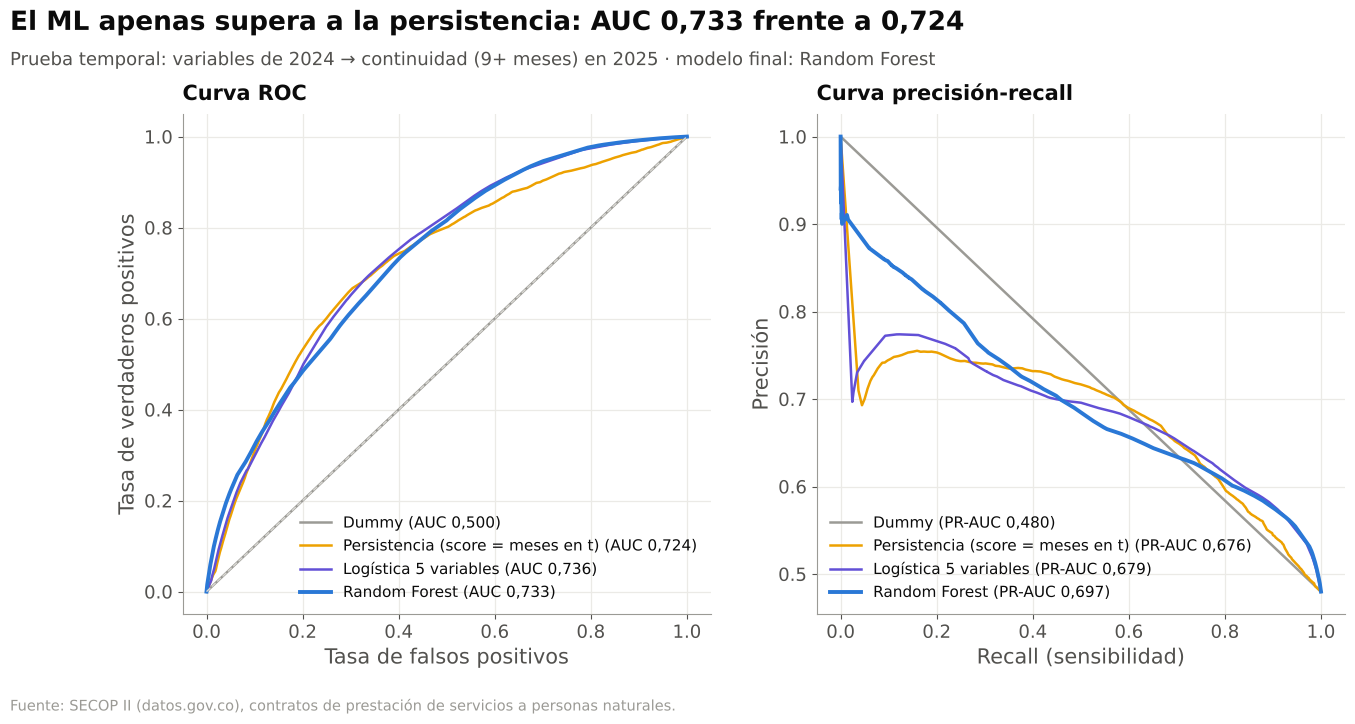

In [10]:
cols_m = {'Dummy': COLOR['gris'], REF: COLOR['amarillo'], 'Logística 5 variables': COLOR['violeta'],
          'Random Forest': COLOR['aqua'], MODELO_FINAL: COLOR['azul']}
if MODELO_FINAL == 'Logística 5 variables':
    cols_m = {'Dummy': COLOR['gris'], REF: COLOR['amarillo'], 'Random Forest': COLOR['aqua'],
              'LightGBM solo persona (A)': COLOR['violeta'], MODELO_FINAL: COLOR['azul']}
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for nombre, c in cols_m.items():
    lw = 2.8 if nombre == MODELO_FINAL else 1.8
    fpr, tpr, _ = roc_curve(y_te, pred_te[nombre])
    axs[0].plot(fpr, tpr, color=c, lw=lw, label=f'{nombre} (AUC {num(res.loc[nombre, "roc_auc"], 3)})')
    pr, rc, _ = precision_recall_curve(y_te, pred_te[nombre])
    axs[1].plot(rc, pr, color=c, lw=lw, label=f'{nombre} (PR-AUC {num(res.loc[nombre, "pr_auc"], 3)})')
axs[0].plot([0, 1], [0, 1], color=COLOR['gris_claro'], ls='--', lw=1)
axs[0].set_xlabel('Tasa de falsos positivos'); axs[0].set_ylabel('Tasa de verdaderos positivos')
axs[1].set_xlabel('Recall (sensibilidad)'); axs[1].set_ylabel('Precisión')
axs[0].set_title('Curva ROC', fontsize=15, pad=10); axs[1].set_title('Curva precisión-recall', fontsize=15, pad=10)
for ax in axs:
    ax.legend(loc='lower right' if ax is axs[0] else 'lower left', fontsize=11); ax.grid(True, axis='both')
fig.suptitle(f'El ML apenas supera a la persistencia: AUC {num(mf.roc_auc, 3)} frente a {num(res.loc[REF, "roc_auc"], 3)}',
             x=0.01, ha='left', fontsize=19, fontweight='bold', y=1.04)
fig.text(0.01, 0.955, f'Prueba temporal: variables de 2024 → continuidad (9+ meses) en 2025 · modelo final: {MODELO_FINAL}',
         fontsize=13, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '04_curvas_roc_pr'); plt.show()

## 4. Matriz de confusión y calibración (modelo final)

Figura guardada: ../outputs/figs/04_matriz_confusion_calibracion.png


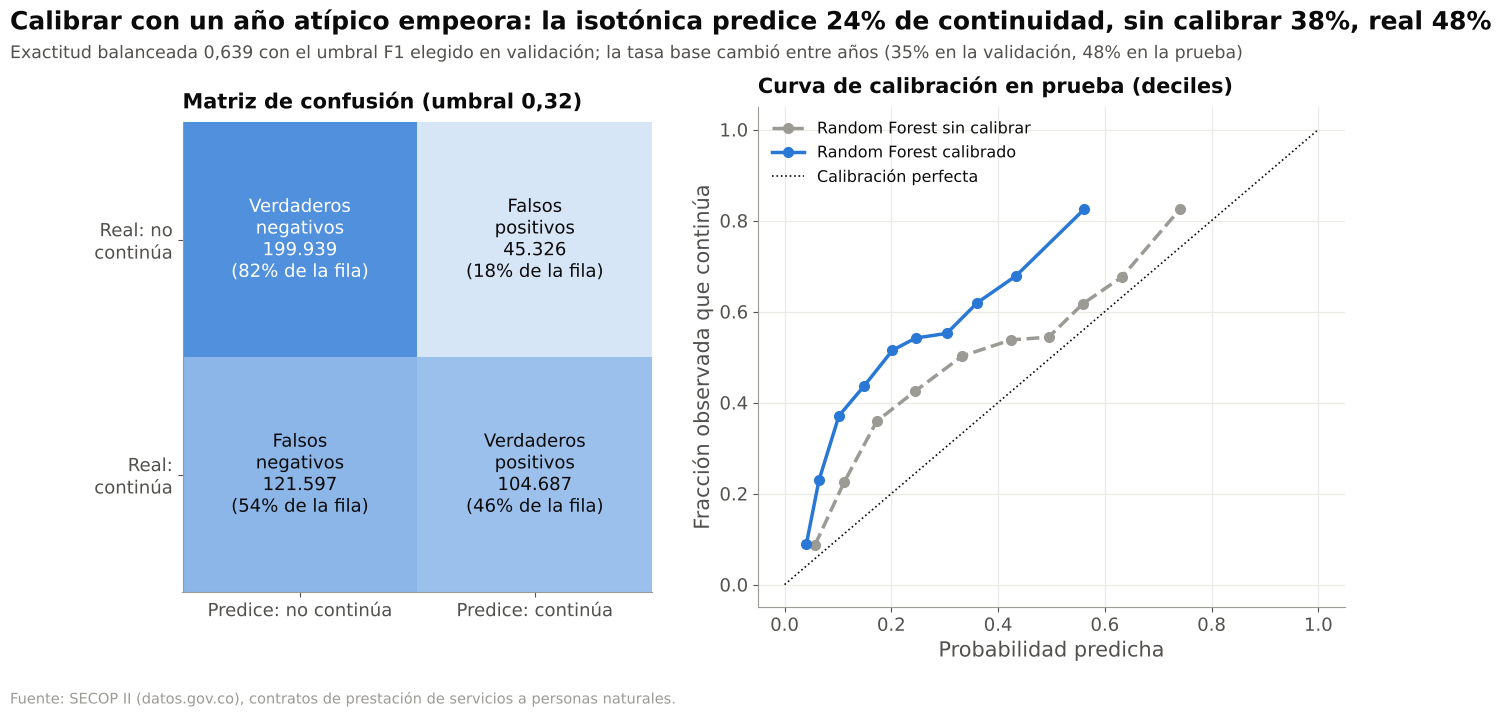

In [11]:
cm = confusion_matrix(y_te, (pred_te[MODELO_FINAL] >= umbrales[MODELO_FINAL]).astype(int))
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axs[0]
cmn = cm / cm.sum(1, keepdims=True)
ax.imshow(cmn, cmap=mpl.colors.LinearSegmentedColormap.from_list('az', ['#ffffff', COLOR['azul']]), vmin=0, vmax=1)
etq = [['Verdaderos\nnegativos', 'Falsos\npositivos'], ['Falsos\nnegativos', 'Verdaderos\npositivos']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{etq[i][j]}\n{num(cm[i, j])}\n({pct(cmn[i, j], 0)} de la fila)', ha='center', va='center',
                fontsize=13, color='white' if cmn[i, j] > 0.55 else COLOR['tinta'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['Predice: no continúa', 'Predice: continúa'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Real: no\ncontinúa', 'Real:\ncontinúa'])
ax.grid(False); ax.set_title(f'Matriz de confusión (umbral {num(umbrales[MODELO_FINAL], 2)})', fontsize=15, pad=10)
ax = axs[1]
fr, mp = calibration_curve(y_te, np.clip(pred_te_cruda[MODELO_FINAL], 0, 1), n_bins=10, strategy='quantile')
ax.plot(mp, fr, marker='o', color=COLOR['gris'], label=f'{MODELO_FINAL} sin calibrar', ms=7, ls='--')
fr, mp = calibration_curve(y_te, pred_te[MODELO_FINAL], n_bins=10, strategy='quantile')
ax.plot(mp, fr, marker='o', color=COLOR['azul'], label=f'{MODELO_FINAL} calibrado', ms=7)
ax.plot([0, 1], [0, 1], color=COLOR['tinta'], ls=':', lw=1.2, label='Calibración perfecta')
ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Fracción observada que continúa')
ax.set_title('Curva de calibración en prueba (deciles)', fontsize=15, pad=10); ax.legend(loc='upper left', fontsize=11.5)
ax.grid(True, axis='both')
fig.suptitle(f'Calibrar con un año atípico empeora: la isotónica predice {pct(pred_te[MODELO_FINAL].mean(), 0)} '
             f'de continuidad, sin calibrar {pct(pred_te_cruda[MODELO_FINAL].mean(), 0)}, real {pct(y_te.mean(), 0)}',
             x=0.01, ha='left', fontsize=18, fontweight='bold', y=1.03)
fig.text(0.01, 0.955, f'Exactitud balanceada {num(res.loc[MODELO_FINAL, "balanced_accuracy"], 3)} con el umbral F1 elegido en validación; '
         'la tasa base cambió entre años (35% en la validación, 48% en la prueba)', fontsize=12.5, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '04_matriz_confusion_calibracion'); plt.show()

**Sobre la calibración.** La curva isotónica se aprendió en la validación (2023→2024, tasa base 35%) y se aplicó
tal cual a la prueba (2024→2025, tasa base 48%). Por eso las probabilidades calibradas quedan **muy por debajo**
de la realidad en todos los deciles. Las probabilidades sin calibrar, que vienen de entrenar con los dos años,
también subestiman, pero menos. No es un error de orden sino un cambio de prevalencia (*prior shift*). En producción
habría que recalibrar cada año con el dato más reciente, o predecir la tasa base del año por separado.

El umbral F1 favorece el recall: predice "continúa" para mucha gente. Por eso su exactitud balanceada puede
quedar por debajo de la de la persistencia con umbral fijo de 9 meses (ver la tabla).

## 5. ¿Qué predice la continuidad? Importancia de variables y SHAP
Usamos el LightGBM con mayor AUC de validación.

Figura guardada: ../outputs/figs/04_importancia_variables.png


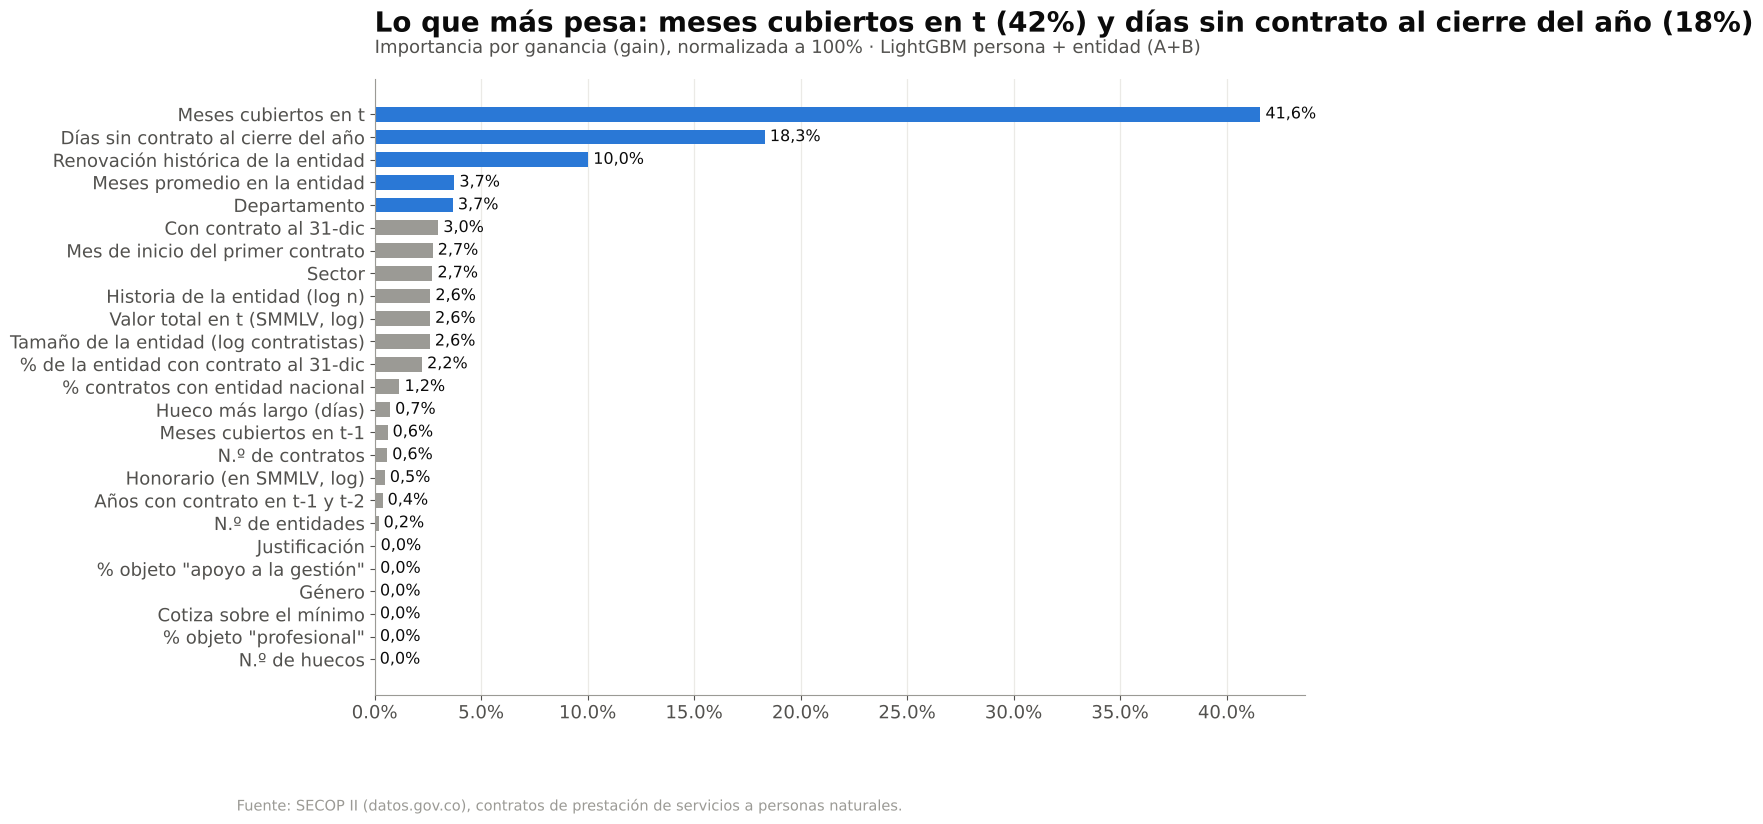

In [12]:
lgbm = modelos_finales[LGB_INTERP]
imp = pd.Series(lgbm.booster_.feature_importance('gain'), index=FEATS_INTERP)
imp = (imp / imp.sum()).sort_values(ascending=True)
imp.rename('importancia_gain').to_csv(TABLAS / '04_importancia_lightgbm.csv')
top2 = list(imp.index[::-1][:2])
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh([NOMBRES_ES[i] for i in imp.index], imp.values,
        color=[COLOR['azul'] if v >= imp.values[-5] else COLOR['gris'] for v in imp.values], height=0.65)
for i, v in enumerate(imp.values):
    ax.text(v, i, ' ' + pct(v), va='center', fontsize=11.5)
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
titulo(ax, f'Lo que más pesa: {NOMBRES_ES[top2[0]].lower()} ({pct(imp[top2[0]], 0)}) y '
           f'{NOMBRES_ES[top2[1]].lower()} ({pct(imp[top2[1]], 0)})',
       f'Importancia por ganancia (gain), normalizada a 100% · {LGB_INTERP}')
fuente(fig); guardar(fig, '04_importancia_variables'); plt.show()

Figura guardada: ../outputs/figs/04_shap_resumen.png


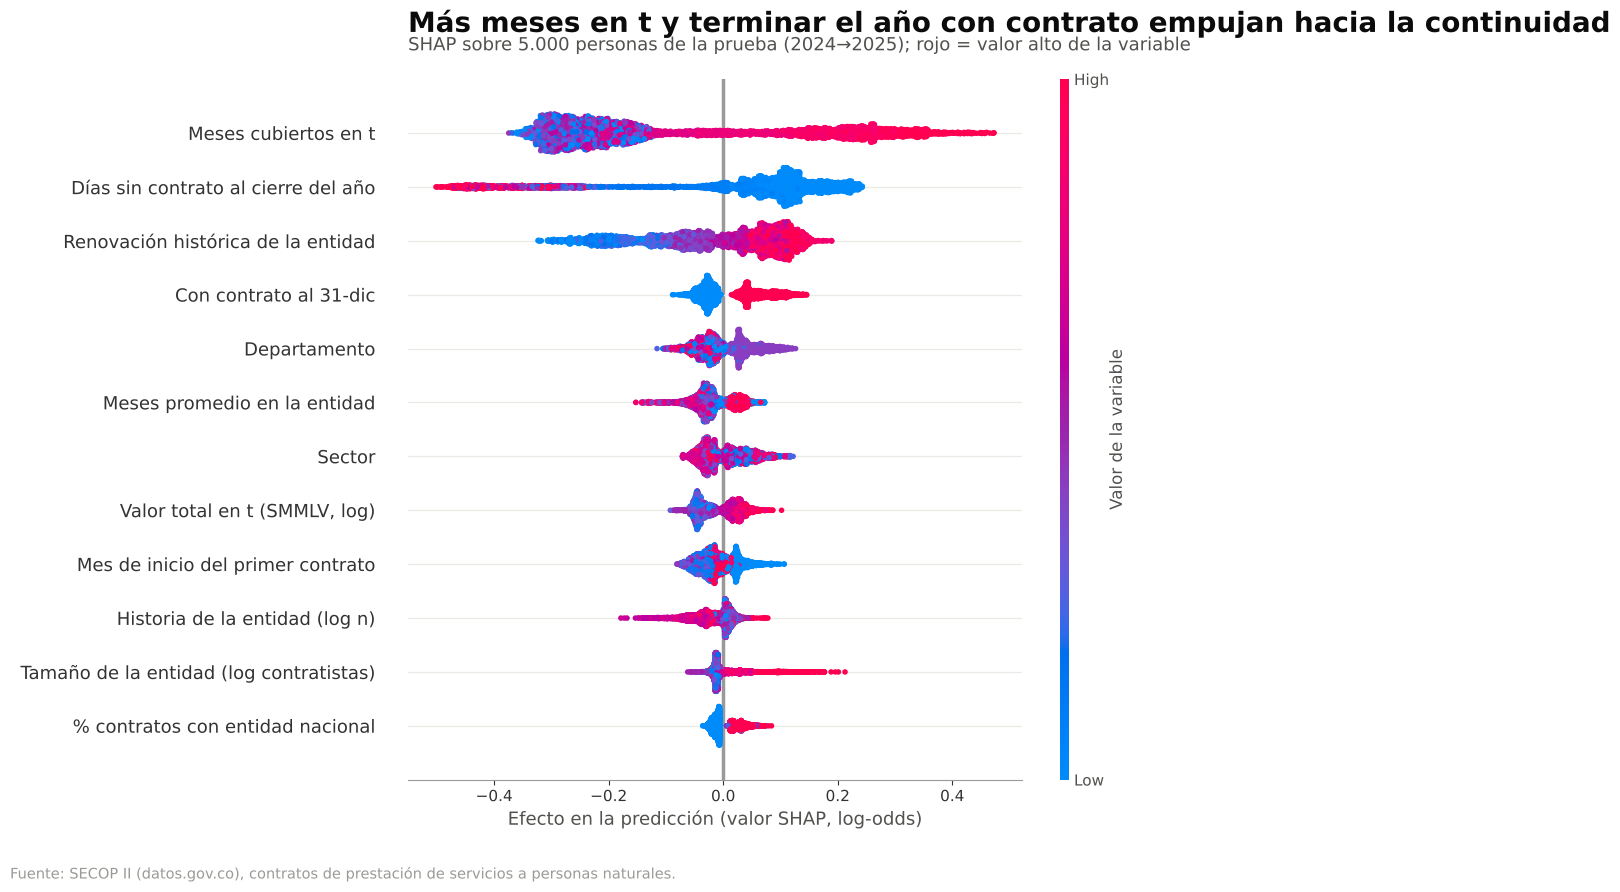

meses_cubiertos                  0.2248
dias_sin_contrato_al_cierre      0.1479
ent_renov_rel                    0.0972
cubierto_al_cierre               0.0446
departamento_modal               0.0370
ent_meses_media                  0.0329
sector_modal                     0.0325
log_valor_total_smmlv            0.0324
mes_inicio_primer_contrato       0.0279
ent_hist_log_n                   0.0262
ent_log_n                        0.0228
share_entidad_nacional           0.0193
ent_pct_cierre                   0.0129
n_contratos                      0.0111
meses_cubiertos_anio_anterior    0.0083
antiguedad_2_anios               0.0068
hueco_max_dias                   0.0060
log_honorario_smmlv              0.0054
n_entidades                      0.0033
justificacion_modal              0.0008
cotiza_minimo                    0.0005
share_objeto_apoyo               0.0005
genero                           0.0003
share_objeto_profesional         0.0002
n_huecos                         0.0000


In [13]:
X_te_i = preparar(pares[2024], FEATS_INTERP)
idx_shap = np.random.default_rng(SEMILLA).choice(len(X_te_i), 5000, replace=False)
Xs = X_te_i.iloc[idx_shap]
sv = shap.TreeExplainer(lgbm).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else sv
shap_abs = pd.Series(np.abs(sv).mean(0), index=FEATS_INTERP).sort_values(ascending=False)
shap_abs.rename('shap_medio_abs').to_csv(TABLAS / '04_shap_importancia.csv')
Xs_plot = Xs.copy()
for c in CAT:
    Xs_plot[c] = Xs_plot[c].cat.codes
Xs_plot.columns = [NOMBRES_ES[c] for c in FEATS_INTERP]
plt.figure()
shap.summary_plot(sv, Xs_plot, max_display=12, show=False, plot_size=(12, 8), color_bar_label='Valor de la variable')
fig = plt.gcf(); ax = plt.gca()
ax.set_xlabel('Efecto en la predicción (valor SHAP, log-odds)')
titulo(ax, 'Más meses en t y terminar el año con contrato empujan hacia la continuidad',
       'SHAP sobre 5.000 personas de la prueba (2024→2025); rojo = valor alto de la variable')
fuente(fig); guardar(fig, '04_shap_resumen'); plt.show()
shap_abs.round(4)

Figura guardada: ../outputs/figs/04_shap_dependencia_top3.png


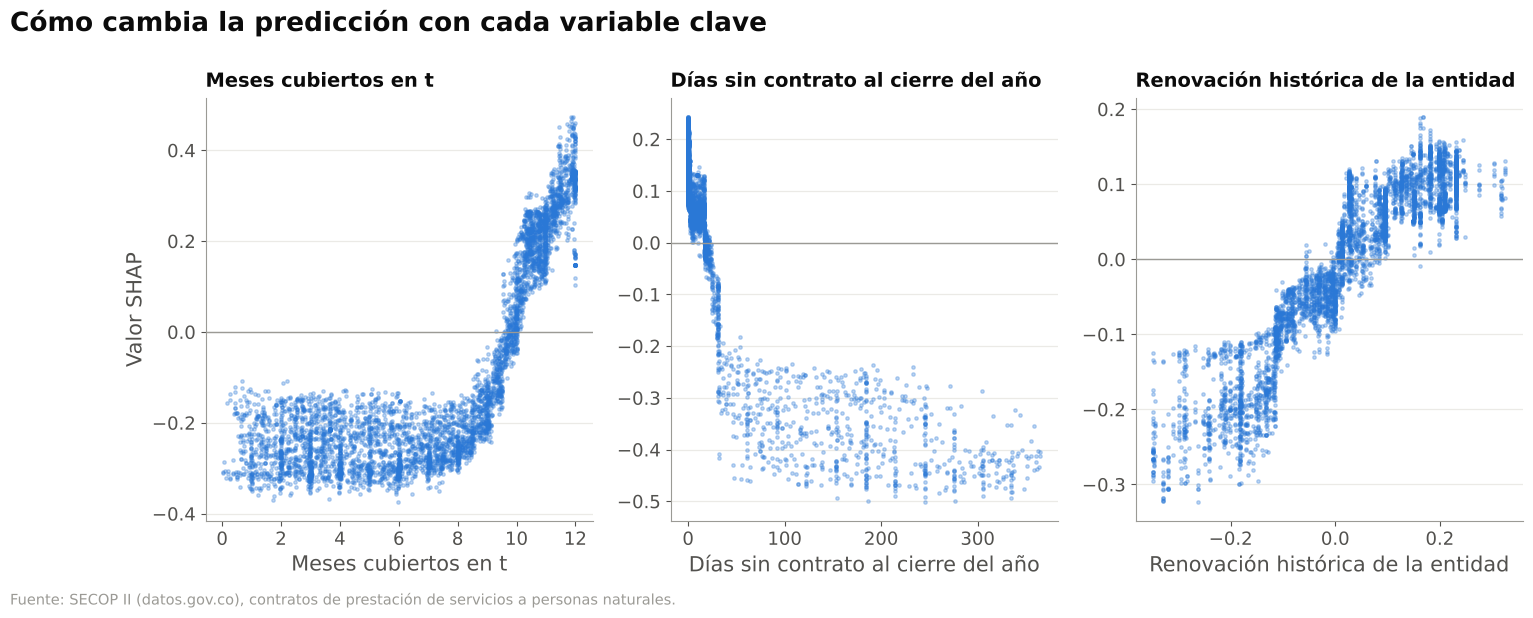

13007

In [14]:
top3 = [c for c in shap_abs.index if c not in CAT][:3]
fig, axs = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, c in zip(axs, top3):
    j = FEATS_INTERP.index(c)
    ax.scatter(Xs[c].astype(float), sv[:, j], s=6, alpha=0.3, color=COLOR['azul'], rasterized=True)
    ax.axhline(0, color=COLOR['gris'], lw=1)
    ax.set_xlabel(NOMBRES_ES[c]); ax.set_title(NOMBRES_ES[c], fontsize=14, pad=8)
axs[0].set_ylabel('Valor SHAP')
fig.suptitle('Cómo cambia la predicción con cada variable clave', x=0.01, ha='left', fontsize=19, fontweight='bold', y=1.04)
fuente(fig); guardar(fig, '04_shap_dependencia_top3'); plt.show()
del X_te_i; gc.collect()

## 6. Sensibilidad: ¿y si el modelo supiera qué contratos ya están firmados para t+1?
`dias_firmados_para_t1` son los días de *t+1* cubiertos por contratos **firmados hasta el 31-dic de t**, usando la
fecha fin original (sin prórrogas). Esa información está disponible a fin de año, pero la dejamos fuera del
modelo principal por dos razones: (i) la fecha fin del registro pudo modificarse después y (ii) hace la
predicción casi trivial para quien ya tiene contrato. Arriba ya está como regla de referencia; aquí la agregamos al
LightGBM.

In [15]:
cols_s = FEATS_INTERP + ['dias_firmados_para_t1']
m_s = nuevo_modelo('LightGBM', None, PARAMS_LGB).fit(preparar(train_all, cols_s), y_tr)
p_s = m_s.predict_proba(preparar(pares[2024], cols_s))[:, 1]
sens = {'auc_sin_compromisos': float(res.loc[LGB_INTERP, 'roc_auc']), 'auc_con_compromisos': float(roc_auc_score(y_te, p_s)),
        'pr_auc_con_compromisos': float(average_precision_score(y_te, p_s)),
        'auc_regla_solo_dias_firmados': float(res.loc['Días ya firmados para t+1', 'roc_auc']),
        'pct_test_con_dias_firmados_t1': float((pares[2024].dias_firmados_para_t1 > 0).mean())}
del m_s; gc.collect()
sens

{'auc_sin_compromisos': 0.7206121507868369,
 'auc_con_compromisos': 0.7380271956213862,
 'pr_auc_con_compromisos': 0.7109984943148474,
 'auc_regla_solo_dias_firmados': 0.7359862038174113,
 'pct_test_con_dias_firmados_t1': 0.10374531596928421}

## 7. Desempeño por grupos (equidad básica)

In [16]:
grupos = pd.DataFrame({'y': y_te, 'p': pred_te_cruda[MODELO_FINAL], 'genero': pares[2024].genero.astype(str).values,
                       'orden': np.where(pares[2024].share_entidad_nacional.values >= 0.5, 'Nacional', 'Territorial')})
eq = []
for col in ['genero', 'orden']:
    for v, d in grupos.groupby(col):
        if len(d) > 1000:
            eq.append({'grupo': f'{col}={v}', 'n': len(d), 'tasa_real': d.y.mean(), 'prob_media': d.p.mean(),
                       'roc_auc': roc_auc_score(d.y, d.p)})
eq = pd.DataFrame(eq); eq.to_csv(TABLAS / '04_desempeno_por_grupo.csv', index=False)
eq.round(3)

,grupo,n,tasa_real,prob_media,roc_auc
0,genero=Hombre,165475,0.448,0.346,0.719
1,genero=Mujer,212300,0.459,0.360,0.720
2,genero=No Definido,93216,0.585,0.471,0.755
3,orden=Nacional,177286,0.517,0.496,0.729
4,orden=Territorial,294263,0.458,0.305,0.755


## 8. Deciles de riesgo (para el notebook de pensión)
**Lectura:** en D1 (mayor riesgo) solo el 9% tuvo 9+ meses en 2025 y el 68% ni siquiera apareció; en D10 el 82%
continuó. El modelo separa los extremos **mejor** que ordenar solo por meses en 2024 (22% y 76%): aunque casi no
mejora el AUC, sí identifica mejor a quienes están en mayor riesgo.

**Convención (la misma del notebook 05):** D1 = **mayor riesgo**, es decir, el 10% con menor probabilidad de
continuidad; D10 = menor riesgo. Para comparar, ordenamos también por la regla de persistencia (meses en *t*). Los
empates se rompen al azar con semilla fija.

Figura guardada: ../outputs/figs/04_deciles_riesgo.png


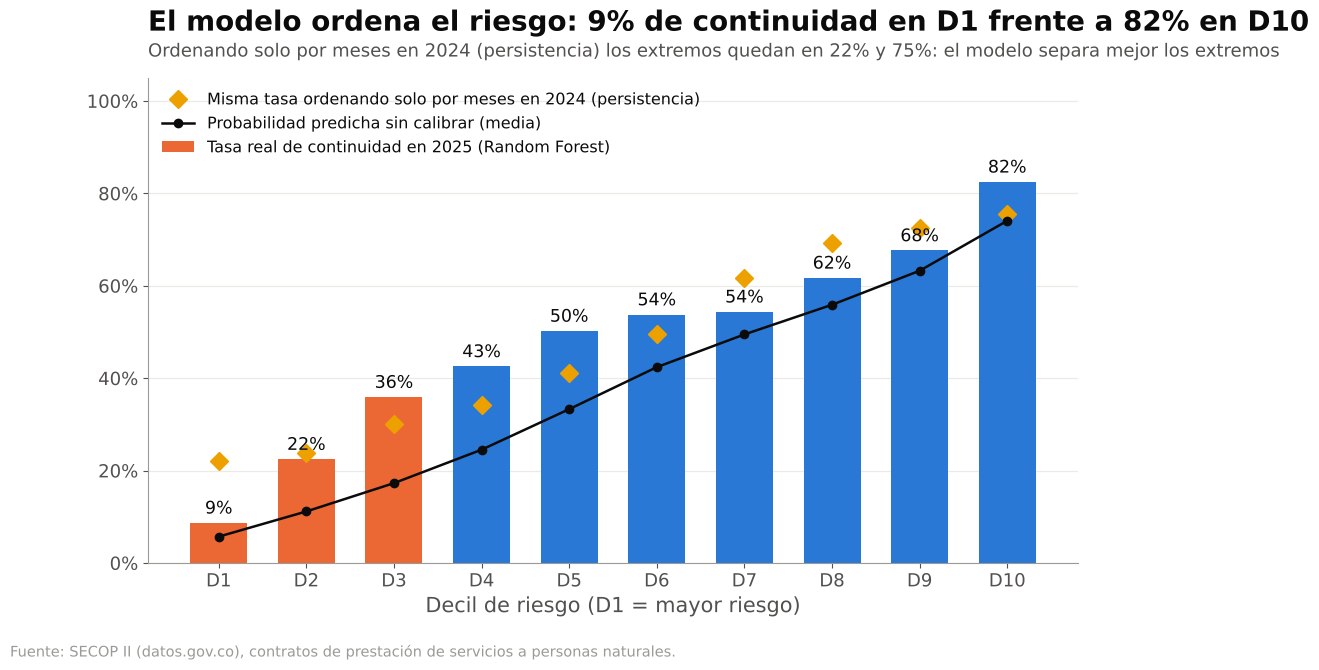

,personas,prob_media,prob_calibrada_media,tasa_real,meses_2024,meses_2025,no_aparece_2025,tasa_real_persistencia
decil_riesgo,,,,,,,,
1,47155,0.057,0.040,0.087,3.610,2.170,0.679,0.221
2,47155,0.111,0.064,0.225,4.945,4.620,0.394,0.237
3,47155,0.173,0.097,0.359,5.813,6.074,0.258,0.301
4,47155,0.245,0.140,0.426,6.345,6.351,0.258,0.343
5,47155,0.333,0.190,0.502,7.101,6.884,0.226,0.411
6,47154,0.424,0.241,0.538,7.347,7.365,0.173,0.496
7,47155,0.495,0.299,0.544,7.409,7.148,0.224,0.617
8,47155,0.559,0.357,0.617,8.556,7.805,0.189,0.692
9,47155,0.632,0.431,0.676,10.174,8.472,0.134,0.725


In [17]:
te = pares[2024][['id_persona', 'meses_cubiertos', 'meses_t1', 'y', 'dias_cubiertos', 'genero']].copy()
te['prob_continuidad'] = pred_te_cruda[MODELO_FINAL]           # sin calibrar (ver la lectura de métricas)
te['prob_calibrada'] = pred_te[MODELO_FINAL]                   # isotónica de la validación 2023→2024
te['score_crudo'] = pred_te_cruda[MODELO_FINAL]
desempate = np.random.default_rng(SEMILLA).random(len(te)) * 1e-9
te['decil_riesgo'] = pd.qcut((te.score_crudo + desempate).rank(method='first'), 10, labels=False) + 1   # 1 = menor prob.
te['decil_persistencia'] = pd.qcut((te.meses_cubiertos + desempate).rank(method='first'), 10, labels=False) + 1
assert te.groupby('decil_riesgo').score_crudo.mean().is_monotonic_increasing      # D1 = menor probabilidad
dec = te.groupby('decil_riesgo').agg(personas=('y', 'size'), prob_media=('prob_continuidad', 'mean'),
                                     prob_calibrada_media=('prob_calibrada', 'mean'),
                                     tasa_real=('y', 'mean'), meses_2024=('meses_cubiertos', 'mean'),
                                     meses_2025=('meses_t1', 'mean'), no_aparece_2025=('meses_t1', lambda x: (x == 0).mean()))
dec['tasa_real_persistencia'] = te.groupby('decil_persistencia').y.mean()
dec.to_csv(TABLAS / '04_deciles_riesgo.csv')
te.to_parquet(INTER / 'predicciones_prueba_2024_2025.parquet', index=False)
# Archivo que consume el notebook 05: probabilidad (sin calibrar) del modelo final y decil (1 = mayor riesgo)
te[['id_persona', 'prob_continuidad', 'decil_riesgo']].rename(columns={'prob_continuidad': 'prob', 'decil_riesgo': 'decil'})\
    .to_parquet(INTER / 'riesgo_2024_2025.parquet', index=False)

fig, ax = plt.subplots(figsize=(12, 6.3))
ax.bar(dec.index, dec.tasa_real, color=[COLOR['naranja'] if d <= 3 else COLOR['azul'] for d in dec.index], width=0.65,
       label=f'Tasa real de continuidad en 2025 ({MODELO_FINAL})')
ax.plot(dec.index, dec.tasa_real_persistencia, color=COLOR['amarillo'], marker='D', lw=0, ms=9,
        label='Misma tasa ordenando solo por meses en 2024 (persistencia)')
ax.plot(dec.index, dec.prob_media, color=COLOR['tinta'], marker='o', lw=1.8, label='Probabilidad predicha sin calibrar (media)')
for d, v in dec.tasa_real.items():
    ax.text(d, v + 0.02, pct(v, 0), ha='center', fontsize=12.5)
ax.set_xticks(dec.index); ax.set_xticklabels([f'D{d}' for d in dec.index])
ax.set_xlabel('Decil de riesgo (D1 = mayor riesgo)'); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1.05)
ax.legend(loc='upper left', fontsize=11.5)
titulo(ax, f'El modelo ordena el riesgo: {pct(dec.tasa_real[1], 0)} de continuidad en D1 frente a {pct(dec.tasa_real[10], 0)} en D10',
       f'Ordenando solo por meses en 2024 (persistencia) los extremos quedan en {pct(dec.tasa_real_persistencia[1], 0)} y '
       f'{pct(dec.tasa_real_persistencia[10], 0)}: el modelo separa mejor los extremos')
fuente(fig); guardar(fig, '04_deciles_riesgo'); plt.show()
dec.round(3)

In [18]:
guardar_resultados('04_supervisado', {
    'objetivo': '1 si meses_cubiertos(t+1) >= 9; 0 si menos o si no aparece en t+1',
    'particion': {'train_final': ['2022→2023', '2023→2024'], 'test': '2024→2025',
                  'validacion': 'entrena 2022→2023, valida 2023→2024 (solo hacia adelante)'},
    'protocolo': 'hiperparametros, calibracion isotonica, umbral F1 y modelo final elegidos en la validacion hacia adelante; prueba usada una sola vez',
    'target_encoding_entidad': '2022→2023: fuera de fold dentro del par (5 folds); 2023→2024: con 2022→2023; prueba: con ambos pares',
    'n': {'train_final': int(len(y_tr)), 'validacion': int(len(y_val)), 'test': int(len(y_te))},
    'tasa_base': {f'{t}→{t+1}': float(d.y.mean()) for t, d in pares.items()},
    'modelo_final': MODELO_FINAL, 'regla_seleccion': 'mayor AUC en validacion 2023→2024 entre los modelos de ML',
    'lightgbm_interpretado': LGB_INTERP,
    'variables_bloques': {'persona_A': NUM_A, 'entidad_B': NUM_B, 'contexto_C': NUM_C, 'logistica_5': NUM_5, 'categoricas': CAT},
    'excluidas_por_leakage': sorted(PROHIBIDAS - {'anio', 'meses_t1', 'y'}),
    'lightgbm_parametros': PARAMS_LGB,
    'tasa_continuidad_observada_t_menos_1_a_t': tasa_obs,
    'metricas_prueba': {m: {k: (float(v) if not isinstance(v, (bool, np.bool_)) else bool(v)) for k, v in f.items()}
                        for m, f in res.iterrows()},
    'mejora_vs_persistencia': {m: {k: float(v) for k, v in f.items()} for m, f in mejora.iterrows()},
    'prob_media_predicha_vs_tasa_real_prueba': {'prob_media_calibrada': float(pred_te[MODELO_FINAL].mean()),
                                                'prob_media_sin_calibrar': float(pred_te_cruda[MODELO_FINAL].mean()),
                                                'tasa_real': float(y_te.mean())},
    'riesgo_2024_2025_parquet': 'id_persona, prob (sin calibrar, modelo final), decil (1 = mayor riesgo)',
    'importancia_gain_top10': imp.sort_values(ascending=False).head(10).to_dict(),
    'shap_top10': shap_abs.head(10).to_dict(),
    'sensibilidad_compromisos_t1': sens,
    'desempeno_por_grupo': eq.to_dict('records'),
    'convencion_deciles': 'D1 = mayor riesgo (menor probabilidad de continuidad)',
    'deciles_riesgo': {int(d): {k: float(v) for k, v in f.items()} for d, f in dec.iterrows()}})

resultados.json -> sección "04_supervisado" actualizada
